# Detecção de fraude em transações de cartão
Projeto didático para comparar modelos em uma base muito desbalanceada. O alvo é Class = 1 (fraude); as métricas centrais são precisão, recall e F1, não apenas acurácia.

A base é carregada diretamente do CSV público do desafio. Time representa segundos decorridos desde a primeira transação; V1 a V28 são componentes PCA anonimizados. O arquivo local creditcard.csv é apenas para conferência e não deve ser enviado ao repositório.


## 1. Bibliotecas e leitura
O endereço é passado diretamente a pandas.read_csv. Se o ambiente não tiver acesso à internet, execute no Google Colab ou configure o acesso ao endereço.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, classification_report, confusion_matrix,
    f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
import shap

RANDOM_STATE = 42
DATA_URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
df = pd.read_csv(DATA_URL)
print(f"Dimensões: {df.shape[0]:,} linhas × {df.shape[1]} colunas")
display(df.head())


Dimensões: 284,807 linhas × 31 colunas


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. Exploração e desbalanceamento
A frequência relativa mostra por que acurácia isolada engana: prever sempre a classe majoritária ainda teria alta acurácia, mas recall zero para fraudes.

In [2]:
display(df["Class"].value_counts().rename(index={0: "normal", 1: "fraude"}).to_frame("quantidade"))
display(df["Class"].value_counts(normalize=True).rename(index={0: "normal", 1: "fraude"}).to_frame("proporção"))
print(f"Valores ausentes: {df.isna().sum().sum()}")
print(f"Taxa de fraude: {df['Class'].mean():.4%}")


,quantidade
Class,
normal,284315
fraude,492


,proporção
Class,
normal,0.998273
fraude,0.001727


Valores ausentes: 0
Taxa de fraude: 0.1727%


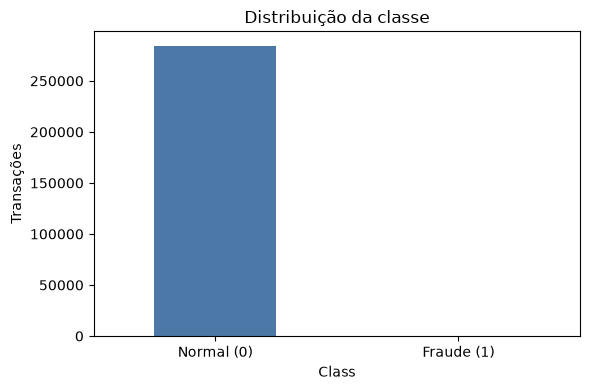

In [3]:
ax = df["Class"].value_counts().sort_index().plot(kind="bar", color=["#4C78A8", "#E45756"], figsize=(6, 4))
ax.set_xticks([0, 1], labels=["Normal (0)", "Fraude (1)"], rotation=0)
ax.set_ylabel("Transações")
ax.set_title("Distribuição da classe")
plt.tight_layout()
plt.show()


## 3. Preparação e divisão
Amount recebe transformação log1p. Mantemos Time e os 28 componentes PCA. A divisão estratificada preserva aproximadamente a proporção de fraudes. O scaler será ajustado dentro do pipeline, apenas nos dados de treino, evitando vazamento.

In [4]:
X = df.drop(columns="Class").copy()
X["Amount"] = np.log1p(X["Amount"])
y = df["Class"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Treino:", X_train.shape, "fraudes:", int(y_train.sum()), f"({y_train.mean():.4%})")
print("Teste:", X_test.shape, "fraudes:", int(y_test.sum()), f"({y_test.mean():.4%})")


Treino: (227845, 30) fraudes: 394 (0.1729%)
Teste: (56962, 30) fraudes: 98 (0.1720%)


## 4. Modelos
Comparamos baseline que sempre prevê normal, regressão logística balanceada, Random Forest com class_weight="balanced" e XGBoost com scale_pos_weight. A padronização é necessária para regressão logística; modelos de árvore são treinados sem ela.

In [5]:
modelos = {
    "Dummy (sempre normal)": DummyClassifier(strategy="most_frequent"),
    "Regressão logística": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=42
    ),
    "XGBoost": XGBClassifier(
        n_estimators=250, max_depth=4, learning_rate=0.08, subsample=0.9,
        colsample_bytree=0.9,
        scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
        eval_metric="logloss", tree_method="hist", n_jobs=-1, random_state=42
    )
}
resultados = {}
for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    prob = modelo.predict_proba(X_test)[:, 1]
    resultados[nome] = {
        "modelo": modelo, "pred": pred, "prob": prob,
        "recall": recall_score(y_test, pred, zero_division=0),
        "precisão": precision_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, prob),
        "PR AUC": average_precision_score(y_test, prob)
    }
comparacao = pd.DataFrame({
    nome: {m: valores[m] for m in ["recall", "precisão", "F1", "ROC AUC", "PR AUC"]}
    for nome, valores in resultados.items()
}).T.sort_values("recall", ascending=False)
display(comparacao.style.format("{:.4f}"))


,recall,precisão,F1,ROC AUC,PR AUC
Regressão logística,0.9184,0.0603,0.1131,0.9711,0.7113
XGBoost,0.8673,0.6911,0.7692,0.9841,0.8644
Random Forest,0.7857,0.9277,0.8508,0.9613,0.8670
Dummy (sempre normal),0.0000,0.0000,0.0000,0.5000,0.0017


In [6]:
for nome, valores in resultados.items():
    print(f"\n### {nome}")
    print(classification_report(y_test, valores["pred"],
        target_names=["normal", "fraude"], zero_division=0))



### Dummy (sempre normal)
              precision    recall  f1-score   support

      normal       1.00      1.00      1.00     56864
      fraude       0.00      0.00      0.00        98

    accuracy                           1.00     56962
   macro avg       0.50      0.50      0.50     56962
weighted avg       1.00      1.00      1.00     56962


### Regressão logística
              precision    recall  f1-score   support

      normal       1.00      0.98      0.99     56864
      fraude       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962


### Random Forest
              precision    recall  f1-score   support

      normal       1.00      1.00      1.00     56864
      fraude       0.93      0.79      0.85        98

    accuracy                           1.00     56962
   macro avg       0.96      0.89      0.93     56962
wei

## 5. Curvas ROC e precisão-recall
A curva precisão-recall evidencia o compromisso entre encontrar fraudes e gerar alertas falsos. A linha horizontal mostra a prevalência da classe fraude no teste.

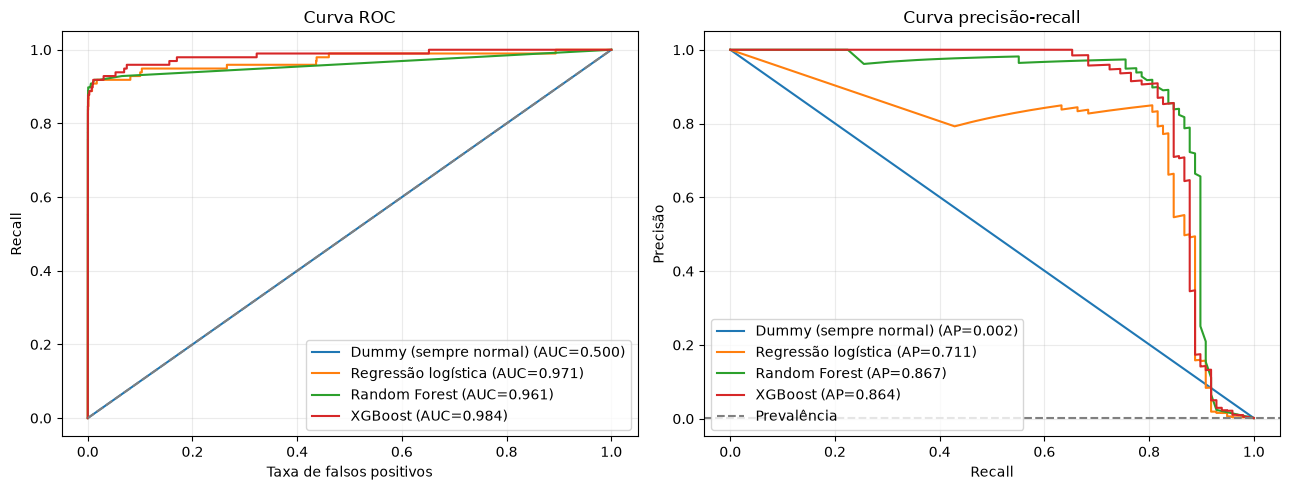

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for nome, valores in resultados.items():
    fpr, tpr, _ = roc_curve(y_test, valores["prob"])
    axes[0].plot(fpr, tpr, label=f"{nome} (AUC={valores['ROC AUC']:.3f})")
    precisao, recall, _ = precision_recall_curve(y_test, valores["prob"])
    axes[1].plot(recall, precisao, label=f"{nome} (AP={valores['PR AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(title="Curva ROC", xlabel="Taxa de falsos positivos", ylabel="Recall")
axes[1].axhline(y_test.mean(), linestyle="--", color="gray", label="Prevalência")
axes[1].set(title="Curva precisão-recall", xlabel="Recall", ylabel="Precisão")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 6. Efeito do limiar
Comparamos 0,5 e 0,3 na regressão logística. Limiar menor tende a aumentar recall, mas também pode aumentar falsos positivos. A escolha final depende de capacidade de revisão e custo dos erros.

In [8]:
prob_lr = resultados["Regressão logística"]["prob"]
linhas = []
for limiar in [0.5, 0.3]:
    pred_limiar = (prob_lr >= limiar).astype(int)
    linhas.append({
        "limiar": limiar,
        "recall": recall_score(y_test, pred_limiar, zero_division=0),
        "precisão": precision_score(y_test, pred_limiar, zero_division=0),
        "F1": f1_score(y_test, pred_limiar, zero_division=0),
        "alertas": int(pred_limiar.sum())
    })
display(pd.DataFrame(linhas).set_index("limiar").style.format("{:.4f}"))


,recall,precisão,F1,alertas
limiar,,,,
0.500000,0.9184,0.0603,0.1131,1493.0000
0.300000,0.9184,0.0262,0.0510,3432.0000


## 7. GridSearchCV por recall
Busca executada só no treino. O scaler está dentro do Pipeline, então cada dobra aprende o scaler apenas na sua partição de treino; o teste é reservado para avaliação.

In [9]:
pipeline_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("modelo", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42))
])
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
busca = GridSearchCV(
    pipeline_lr, param_grid={"modelo__C": [0.1, 1.0, 10.0]},
    scoring="recall", cv=cv, n_jobs=-1, refit=True
)
busca.fit(X_train, y_train)
print("Melhores parâmetros:", busca.best_params_)
print(f"Recall médio na validação cruzada: {busca.best_score_:.4f}")
prob_ajustada = busca.best_estimator_.predict_proba(X_test)[:, 1]
pred_ajustada = (prob_ajustada >= 0.3).astype(int)
print("\nRelatório no teste (limiar = 0,3):")
print(classification_report(y_test, pred_ajustada,
    target_names=["normal", "fraude"], zero_division=0))
display(pd.DataFrame(confusion_matrix(y_test, pred_ajustada),
    index=["real normal", "real fraude"],
    columns=["previsto normal", "previsto fraude"]))


Melhores parâmetros: {'modelo__C': 0.1}
Recall médio na validação cruzada: 0.8984

Relatório no teste (limiar = 0,3):
              precision    recall  f1-score   support

      normal       1.00      0.94      0.97     56864
      fraude       0.03      0.92      0.05        98

    accuracy                           0.94     56962
   macro avg       0.51      0.93      0.51     56962
weighted avg       1.00      0.94      0.97     56962



,previsto normal,previsto fraude
real normal,53542,3322
real fraude,8,90


## 8. Importância das variáveis
Importância por impureza da Random Forest é uma visão global e pode favorecer certos tipos de variáveis. V1–V28 são componentes PCA anonimizados; a importância não revela diretamente um significado de negócio.

,importância
V14,0.181220
V4,0.117300
V10,0.108266
V12,0.098100
V17,0.087768
V3,0.062882
V16,0.054004
V11,0.051953
V2,0.030927
V7,0.021247


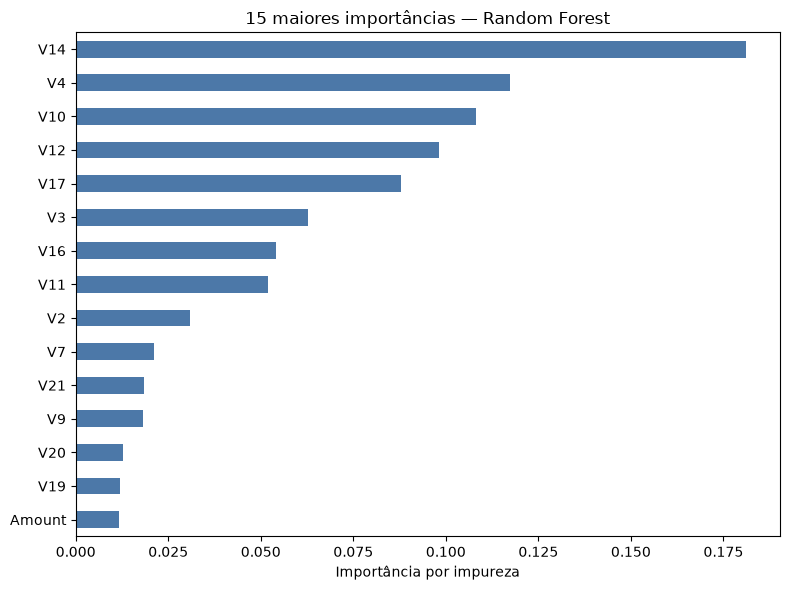

In [10]:
rf = resultados["Random Forest"]["modelo"]
importancias = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
display(importancias.head(15).to_frame("importância"))
importancias.head(15).sort_values().plot(kind="barh", figsize=(8, 6), color="#4C78A8")
plt.title("15 maiores importâncias — Random Forest")
plt.xlabel("Importância por impureza")
plt.tight_layout()
plt.show()


## 9. SHAP
TreeExplainer avalia o XGBoost em amostra do teste para limitar o custo. O beeswarm resume contribuições; o waterfall explica uma fraude real do teste, se presente. Por padrão, TreeExplainer explica a saída bruta do XGBoost (log-odds em classificação binária); SHAP explica o modelo, não causalidade nem o significado original dos componentes PCA.

Amostra SHAP: 98 fraudes e 1000 transações normais.


,SHAP médio absoluto
V14,2.043247
V4,1.530369
V10,0.674438
V12,0.659086
V8,0.485181
V3,0.413688
V11,0.402007
V26,0.387153
V16,0.386149
V7,0.351450


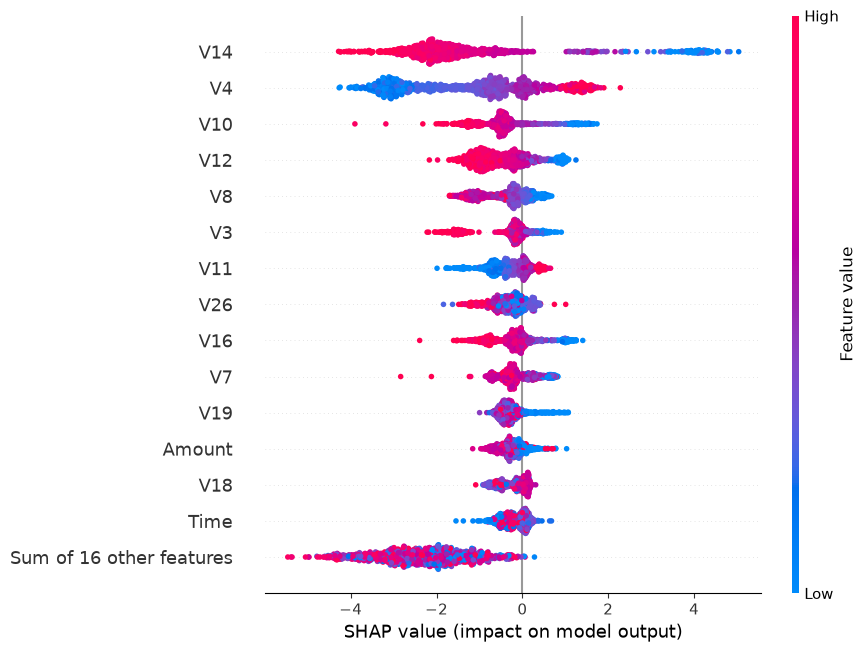

In [11]:
modelo_xgb = resultados["XGBoost"]["modelo"]
indices_fraude_teste = y_test[y_test == 1].index
indices_normais = y_test[y_test == 0].sample(n=min(1000, int((y_test == 0).sum())), random_state=42).index
X_shap = pd.concat([X_test.loc[indices_normais], X_test.loc[indices_fraude_teste]]).sample(frac=1, random_state=42)
print(f"Amostra SHAP: {int((y_test.loc[X_shap.index] == 1).sum())} fraudes e {int((y_test.loc[X_shap.index] == 0).sum())} transações normais.")
explainer = shap.TreeExplainer(modelo_xgb)
shap_values = explainer(X_shap)
if shap_values.values.ndim == 3:
    shap_fraude = shap_values[:, :, 1]
else:
    shap_fraude = shap_values
shap_importancia = pd.Series(np.abs(shap_fraude.values).mean(axis=0), index=X.columns).sort_values(ascending=False)
display(shap_importancia.head(10).to_frame("SHAP médio absoluto"))
shap.plots.beeswarm(shap_fraude, max_display=15)


Exemplo de transação fraudulenta: linha 8972, probabilidade estimada = 0.8170.


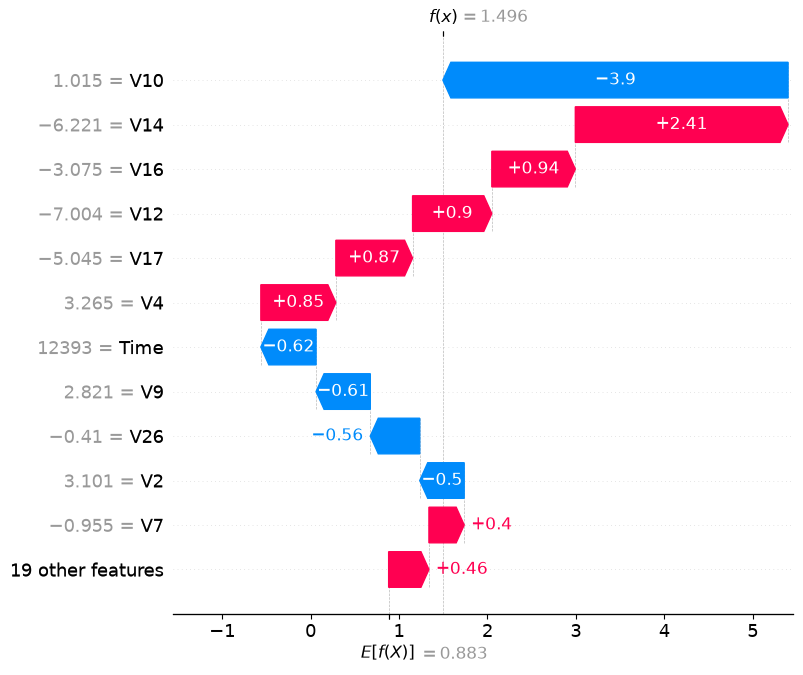

In [12]:
indices_fraude = np.flatnonzero(y_test.loc[X_shap.index].to_numpy() == 1)
if len(indices_fraude):
    idx_local = int(indices_fraude[0])
    indice_linha = X_shap.index[idx_local]
    probabilidade = modelo_xgb.predict_proba(X_shap.loc[[indice_linha]])[0, 1]
    print(f"Exemplo de transação fraudulenta: linha {indice_linha}, probabilidade estimada = {probabilidade:.4f}.")
    shap.plots.waterfall(shap_fraude[idx_local], max_display=12)
else:
    print("Não houve fraude na amostra SHAP selecionada.")


## 10. Conclusões e limites
Compare recall junto com precisão e F1. Aumentar recall costuma aumentar alertas; a escolha do limiar depende de política operacional/custo não fornecido neste exercício. A divisão aleatória estratificada segue o briefing, mas não avalia robustez a mudanças futuras. Para produção, valide também com corte temporal e monitore mudança de distribuição.

In [13]:
melhor_por_recall = comparacao["recall"].idxmax()
print("Maior recall entre os modelos de referência:", melhor_por_recall)
display(comparacao.loc[[melhor_por_recall]])
print("O limiar é decisão operacional: considere precisão, F1 e quantidade de alertas.")


Maior recall entre os modelos de referência: Regressão logística


,recall,precisão,F1,ROC AUC,PR AUC
Regressão logística,0.918367,0.060281,0.113136,0.971117,0.711314


O limiar é decisão operacional: considere precisão, F1 e quantidade de alertas.
